# <b>Task 2.1 - Unconditional Baseline.</b>

Baseline maker PnL across all trades without any filtering. This is the reference point - every class/feature discovered later must improve upon these numbers.

**Metrics:**
- Weighted PnL: `PnL_all(τ) = Σ(w_i × pnl_i) / Σ(w_i)` - the number to beat.
- Unweighted statistics: mean, std, quantiles - distribution shape.
- Histograms and boxplots - visual confirmation of heavy tails.

## <b> Import Libraries.</b>

In [1]:
import polars as pl
import matplotlib.pyplot as plt

In [2]:
# Params.
HORIZONS            = [30, 120, 300]
REBATE_BPS          = 0.5
CLIPPED_BOUND       = 100_000

## <b> Global Variables.</b>

In [3]:
# Paths for BTCUSDT.
PATH_BINANCE_PERP_BTCUSDT_LOB       = r'data\binance_booktickers\perp_btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_LIQUID    = r'data\binance_liquidations\perp_btcusdt.parquet'
PATH_BYBIT_PERP_BTCUSDT_LIQUID      = r'data\bybit_liquidations\btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_TRADES    = r'data\binance_trades\perp_btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_MARKOUT   = r'data\processed\btc_markout.parquet'

# Paths for ETHUSDT.
PATH_BINANCE_PERP_ETHUSDT_LOB       = r'data\binance_booktickers\perp_ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_LIQUID    = r'data\binance_liquidations\perp_ethusdt.parquet'
PATH_BYBIT_PERP_ETHUSDT_LIQUID      = r'data\bybit_liquidations\ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_TRADES    = r'data\binance_trades\perp_ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_MARKOUT   = r'data\processed\eth_markout.parquet'

# All .parquet files.
PARQUET_FILES = {
    "binance_perp_btcusdt_lob": PATH_BINANCE_PERP_BTCUSDT_LOB,
    "binance_perp_btcusdt_liquid": PATH_BINANCE_PERP_BTCUSDT_LIQUID,
    "bybit_perp_btcusdt_liquid": PATH_BYBIT_PERP_BTCUSDT_LIQUID,
    "binance_perp_btcusdt_trades": PATH_BINANCE_PERP_BTCUSDT_TRADES,
    "binance_perp_btcusdt_markout": PATH_BINANCE_PERP_BTCUSDT_MARKOUT,

    "binance_perp_ethusdt_lob": PATH_BINANCE_PERP_ETHUSDT_LOB,
    "binance_perp_ethusdt_liquid": PATH_BINANCE_PERP_ETHUSDT_LIQUID,
    "bybit_perp_ethusdt_liquid": PATH_BYBIT_PERP_ETHUSDT_LIQUID,
    "binance_perp_ethusdt_trades": PATH_BINANCE_PERP_ETHUSDT_TRADES,
    "binance_perp_ethusdt_markout": PATH_BINANCE_PERP_ETHUSDT_MARKOUT
}

In [4]:
lf_markout = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_MARKOUT)

## <b>Weighted PnL - Baseline.</b>

Weighted average maker PnL across all trades. This is `PnL_all(τ)` from the scoring formula. Negative value means the maker loses on average (adverse selection exceeds rebate).

In [5]:
# calculate weighted PNL.
def weighted_pnl(
    lf: pl.LazyFrame
) -> pl.DataFrame:
    """
    Calculate weighted PNL.
    """
    
    df = (
        lf.select(
            ((pl.col("weight") * pl.col("pnl_30s")).sum() / pl.col("weight").sum()).alias("w_pnl_30s"),
            ((pl.col("weight") * pl.col("pnl_120s")).sum() / pl.col("weight").sum()).alias("w_pnl_120s"),
            ((pl.col("weight") * pl.col("pnl_300s")).sum() / pl.col("weight").sum()).alias("w_pnl_300s")
        )
    ).collect(engine="streaming")

    return df

In [6]:
# calculate weighted PNL.
df_w_pnl = weighted_pnl(lf_markout)

# show results.
display(df_w_pnl)

w_pnl_30s,w_pnl_120s,w_pnl_300s
f32,f32,f32
-0.105104,-0.037397,0.009115


## <b>PnL Distribution Statistics.</b>

Unweighted per-trade statistics. Heavy tails (large std, extreme quantiles) confirm that a small fraction of trades drives the average loss.

In [7]:
# calculate statistics.
def pnl_stats_exprs(h: int):
    col = f"pnl_{h}s"

    return [
        pl.col(col).mean().alias("mean"),
        pl.col(col).std().alias("std"),
        pl.col(col).quantile(0.05).alias("q_5"),
        pl.col(col).quantile(0.25).alias("q_25"),
        pl.col(col).quantile(0.50).alias("q_50"),
        pl.col(col).quantile(0.75).alias("q_75"),
        pl.col(col).quantile(0.95).alias("q_95"),
        pl.col(col).count().alias("n"),
    ]

def pnl_statistics(
    lf: pl.LazyFrame
):
    """
    Return:
    - pl.DataFrame with PNL statistics for differnt horizons.
    - plt.Figure with PNL boxplots for differnt horizons.
    - plt.Figure with PNL Histograms for differnt horizons.
    """

    # calculate statistics for different horizons.
    dfs = []

    for horizon in HORIZONS:
        df_h = (
            lf
            .select(
                pl.lit(f"{horizon}s").alias("horizon"),
                *pnl_stats_exprs(horizon)
            )
            .collect(engine="streaming")
        )

        dfs.append(df_h)

    df_stats = pl.concat(dfs)

    df_stats = df_stats.with_columns(
        pl.col(["mean", "std", "q_5", "q_25", "q_50", "q_75", "q_95"]).round(4)
    )


    # plot charts - PNL distributions.
    pnl_data = (
        lf
        .select([f"pnl_{tau}s" for tau in HORIZONS])
        .collect(engine="streaming")
    )

    fig_histograms, axes_histogram = plt.subplots(1, 3, figsize=(15, 4))
    for ax, tau in zip(axes_histogram, HORIZONS):
        col = f"pnl_{tau}s"
        data = pnl_data[col].to_numpy()
        ax.hist(data, bins=200, edgecolor="none", alpha=0.7)
        ax.axvline(0, color="red", linestyle="--", linewidth=0.8)
        ax.set_title(f"Markout {tau}s")
        ax.set_xlabel("PnL (bps)")


    fig_boxplots, ax_boxplots = plt.subplots(figsize=(8, 4))
    box_data = [pnl_data[f"pnl_{tau}s"].to_numpy() for tau in HORIZONS]
    ax_boxplots.boxplot(box_data, tick_labels=[f"{tau}s" for tau in HORIZONS], showfliers=False)
    ax_boxplots.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax_boxplots.set_ylabel("PnL (bps)")
    ax_boxplots.set_title("Markout distribution by horizon")


    return df_stats, fig_histograms, fig_boxplots

horizon,mean,std,q_5,q_25,q_50,q_75,q_95,n
str,f32,f32,f32,f32,f32,f32,f32,u32
"""30s""",-0.2172,9.3051,-13.2432,-3.6996,-0.0738,3.3585,12.5404,804035257
"""120s""",-0.1788,16.7171,-24.9394,-6.99,-0.0299,6.7388,24.231701,804035257
"""300s""",-0.1418,24.8829,-37.651199,-10.6677,-0.0005,10.5373,36.892799,804035257


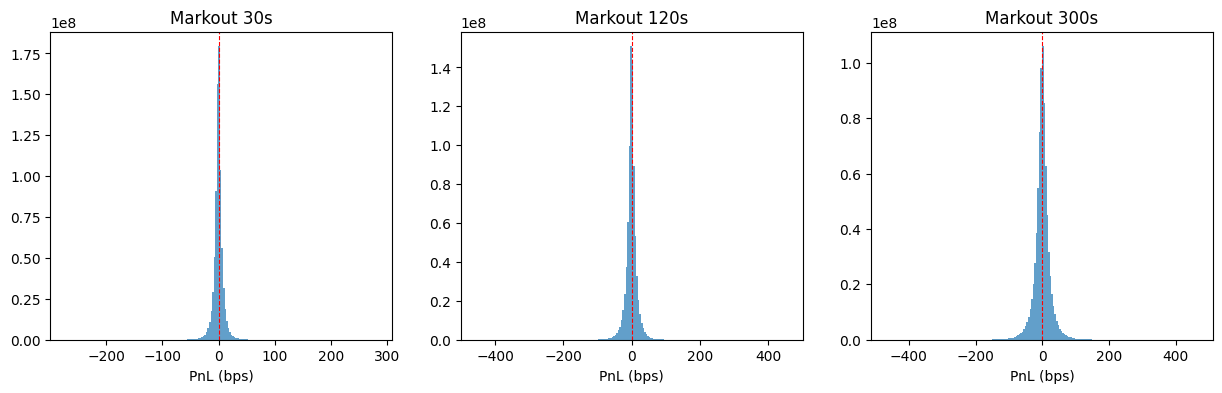

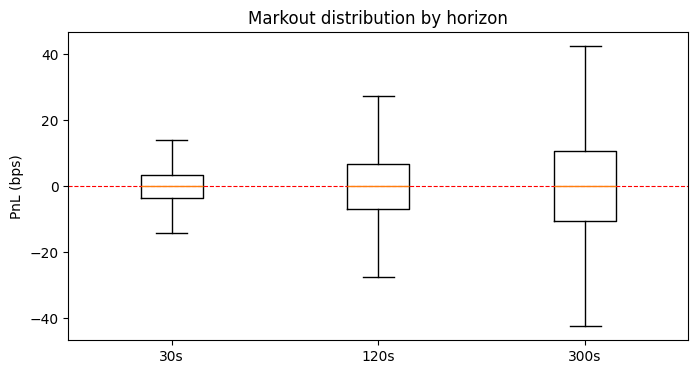

In [8]:
# calculate statistics.
df_pnl_stats, fig_pnl_histograms, fig_pnl_boxplots = pnl_statistics(lf_markout)

# show results.
display(df_pnl_stats)
plt.show(fig_pnl_boxplots)
plt.show(fig_pnl_histograms)

## <b>PnL Distribution - Visualization.</b>

Histograms show a sharp peak at zero with fat tails. Boxplots confirm that variance grows with horizon (30s -> 300s), as expected.